In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

#from gauss_slicer import * 

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from slicing_class import adcFitter2

In [2]:
#import data
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov9th/counterrotation.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/zband/z_sparkles_counter_sat.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov5th/counterrotation.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov11th_onsky/onsky_counterrotation.fits')

In [3]:
for img in step: #the dark subtraction isn't working so i had to median subtract the image... should I do this onsky?
       img -= np.median(img)

In [4]:
len(step)

51

In [5]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle,snr_threshold=2.6,speckle_window=50) 

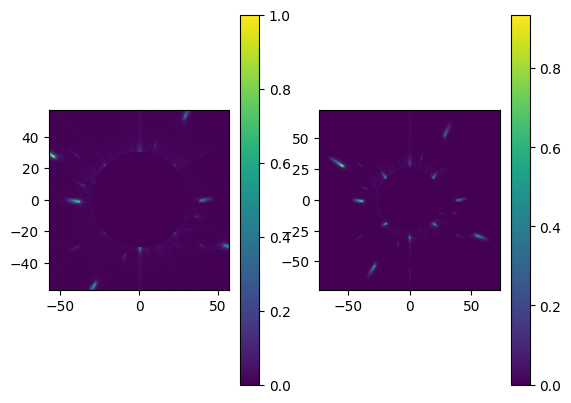

In [6]:
plt.subplot(1,2,1)
imshow_field(ADC.crop_image(step[1]))
plt.colorbar()
plt.subplot(1,2,2)
imshow_field(ADC.filter_image(ADC.crop_image(step[1],mask_diam=50,extent=512)))
plt.colorbar()

In [7]:
#dispersion vector estimator
def est_mag_dir(psf,plotted=False,printed=False):
    slopes = np.zeros(4)
    intercepts = np.zeros(4)
    points = []
    lines = np.zeros((4,3))

    for i in range(4):
        #print(ADC.slice_speckle_angle(psf,i,positions=True))
        try:
            angle,point = ADC.slice_speckle_angle(psf,i,positions=True)
        except:
            print(f'fitting not successful for speckle {i}')
            return np.nan
        if i == 0 or i ==2:
            angle = 90 - angle

        slope = np.tan(np.radians(angle))
        slopes[i] = slope
        points.append(point)
        intercepts[i] = -slope * point[0] + point[1]

    for j in range(4):
        lines[j,0] = slopes[j]
        lines[j,1] = -1
        lines[j,2] = points[j][1] - slopes[j]*points[j][0]

    A = lines[:,0]
    B = lines[:,1]
    C = lines[:,2]
    norm = np.sqrt(A**2 + B**2)

    A /= norm
    B /= norm
    C /= norm

    M = np.stack((A.T,B.T),axis=1)
    C = -C

    (x, y), *_ = np.linalg.lstsq(M, C)
    if printed:
        print(f'least-squares solution: ({x},{y})')
    magnitude_guess = np.sqrt(x**2+y**2) 

    #added logic for quadrants
    if x > 0 and y > 0: #i
        orientation_guess = np.degrees(np.atan(y/x))
    elif x < 0 and y >0: #ii
        orientation_guess = 180+np.degrees(np.atan(y/x))
    elif x < 0 and y < 0: #iii
        orientation_guess = -np.degrees(np.atan(y/x))
    else: #iv
        orientation_guess = -180-np.degrees(np.atan(y/x))

    if printed:  
        print(f'Estimated dispersion direction {orientation_guess}°')
        print(f'Estimated dispersion magnitude {magnitude_guess}')

    if plotted:
        imshow_field(psf)
        a = np.array(psf.grid.x)

        for i in range(4):
            plt.plot(a, slopes[i] * a + intercepts[i],'w--',linewidth=0.5)

        plt.plot(x,y,'o',color='orange',label='dispersed speckle center')
        plt.plot(0,0,'o',color='red',label='psf center')

        plt.xlim((-60,60))
        plt.ylim((-60,60))
        plt.legend(loc='upper right')
        
    return magnitude_guess,orientation_guess

In [8]:
#testing the newer version of that function
def est_mag_dir(psf,plotted=False):
    slopes = np.zeros(4)
    intercepts = np.zeros(4)
    points = []
    lines = np.zeros((4,3))

    for i in range(4):
        #print(ADC.slice_speckle_angle(psf,i,positions=True))
        try:
            angle,point = ADC.slice_speckle_angle(psf,i,positions=True)
        except:
            print(f'fitting not successful for speckle {i}')
            return np.nan
        if i == 0 or i ==2:
            angle = 90 - angle

        slope = np.tan(np.radians(angle))
        slopes[i] = slope
        points.append(point)
        intercepts[i] = -slope * point[0] + point[1]

    for j in range(4):
        lines[j,0] = slopes[j]
        lines[j,1] = -1
        lines[j,2] = points[j][1] - slopes[j]*points[j][0]

    A = lines[:,0]
    B = lines[:,1]
    C = lines[:,2]
    norm = np.sqrt(A**2 + B**2)

    A /= norm
    B /= norm
    C /= norm

    M = np.stack((A.T,B.T),axis=1)
    C = -C

    (x, y), *_ = np.linalg.lstsq(M, C)
    print(f'least-squares solution: ({x},{y})')
    magnitude_guess = np.sqrt(x**2+y**2) / 100

    #added logic for quadrants
    if x > 0 and y > 0: #i
        orientation_guess = np.degrees(np.atan(y/x))
    elif x < 0 and y >0: #ii
        orientation_guess = 180+np.degrees(np.atan(y/x))
    elif x < 0 and y < 0: #iii
        orientation_guess = -np.degrees(np.atan(y/x))
    else: #iv
        orientation_guess = -180-np.degrees(np.atan(y/x))

    print(f'Estimated dispersion direction {orientation_guess}°')
    print(f'Estimated dispersion magnitude {magnitude_guess}')

    if plotted:
        imshow_field(psf)
        a = np.array(psf.grid.x)

        for i in range(4):
            plt.plot(a, slopes[i] * a + intercepts[i],'w--',linewidth=0.5)

        plt.plot(x,y,'o',color='orange',label='dispersed speckle center')
        plt.plot(0,0,'o',color='red',label='psf center')

        plt.xlim((-60,60))
        plt.ylim((-60,60))
        #plt.legend(loc='upper right')
        
    return magnitude_guess,orientation_guess

slope: 0.37
corresponding angle: 0.36 (rad) or 20.41°
least-squares solution: (1.6811450294800343,-9.37267918720245)
Estimated dispersion direction -100.16881425752584°
Estimated dispersion magnitude 0.09522256232446352


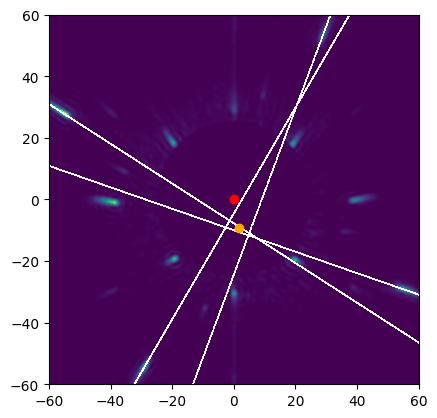

In [9]:
h = ADC.filter_image(ADC.crop_image(step[0],mask_diam=50,extent=600))
q,r = ADC.slice_speckle_angle(h,0,print_updates=True,positions=True)
r = est_mag_dir(h,plotted=True)
#plt.colorbar()

In [10]:
mags =[]
angs = []
misses = []

for i,img in enumerate(step):
    img = ADC.filter_image(ADC.crop_image(img,extent=512))
    try:
        mag,ang = est_mag_dir(img,plotted=False)
        mags.append(mag)
        angs.append(ang)
    except: 
        misses.append(i)
        pass


least-squares solution: (1.6692976167344569,-9.366897785472926)
Estimated dispersion direction -100.10473695322182°
Estimated dispersion magnitude 0.09514479946730296
least-squares solution: (1.6848182394614453,-9.308057722516814)
Estimated dispersion direction -100.25981805786012°
Estimated dispersion magnitude 0.09459310284884774
least-squares solution: (2.134155165274625,-8.779142862893753)
Estimated dispersion direction -103.66322249523164°
Estimated dispersion magnitude 0.09034819736805305
least-squares solution: (1.8850863003606089,-8.510494990732418)
Estimated dispersion direction -102.48944353345581°
Estimated dispersion magnitude 0.08716769777107163
least-squares solution: (2.329650851413092,-8.330994760476756)
Estimated dispersion direction -105.62293580029935°
Estimated dispersion magnitude 0.08650592279640794
least-squares solution: (1.7697633387459262,-7.888903704551428)
Estimated dispersion direction -102.64415495241103°
Estimated dispersion magnitude 0.08084977670646616


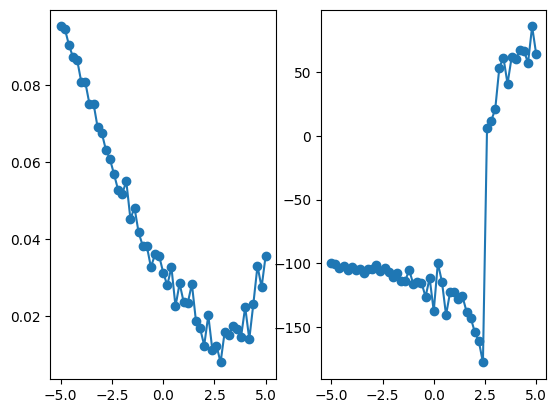

In [11]:
mags = np.array(mags)
angs = np.array(angs)

angle_offsets = np.linspace(-5,5,51)
angle_offsets = np.delete(angle_offsets,misses)

plt.subplot(1,2,1)
plt.plot(angle_offsets,mags,'-o')
plt.subplot(1,2,2)
plt.plot(angle_offsets,angs,'-o')

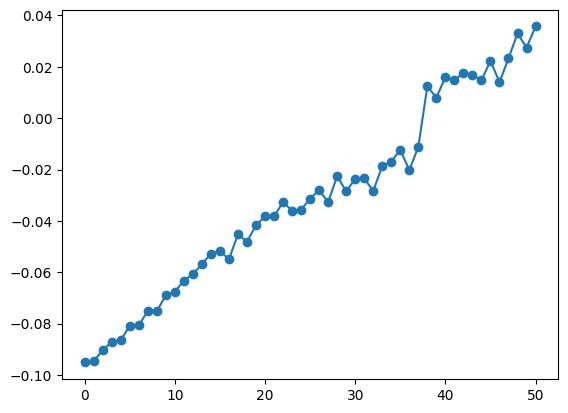

In [12]:
#to make the linear response, we need to take into account both the magnitude and the orientation. 
#could multiply the magnitude by the sign of the orientation to make it a straight line?
signs = np.sign(angs)
mags_lin = mags * signs.T
plt.plot(mags_lin,'-o')

Slope of Magnitude Response: 0.012437757029080215
Offset of Magnitude Response: -0.03137839974810496


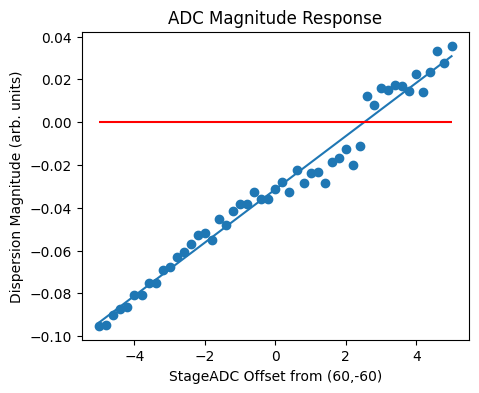

In [13]:
#now fit the magnitude response

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)

m1 , b1 = np.polyfit(angle_offsets,mags_lin,deg=1)
plt.scatter(angle_offsets,mags_lin)
linepoints = b1 + m1 * angle_offsets
plt.plot(angle_offsets, linepoints)
plt.hlines(0,-5,5,color='red')
print(f'Slope of Magnitude Response: {m1}')
print(f'Offset of Magnitude Response: {b1}')


plt.title('ADC Magnitude Response')
plt.xlabel('StageADC Offset from (60,-60)')
plt.ylabel('Dispersion Magnitude (arb. units)')
plt.show()

In [14]:
#now do a co-rotation cube to measure the orientation response
cube = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/corotation_calibs/corotation_3offset_m5to5.fits')
for img in cube: #the dark subtraction isn't working so i had to median subtract the image... should I do this onsky?
       img -= np.median(img)

In [15]:
h = ADC.filter_image(ADC.crop_image(cube[0],mask_diam=50,extent=500))
q,r = ADC.slice_speckle_angle(h,0,print_updates=True,positions=True)
r = est_mag_dir(h,plotted=True,printed=True)

slope: 0.56
corresponding angle: 0.51 (rad) or 29.32°


TypeError: est_mag_dir() got an unexpected keyword argument 'printed'

In [ ]:
mags =[]
angs = []
misses = []

for i,img in enumerate(cube):
    img = ADC.filter_image(ADC.crop_image(img,extent=510))
    try:
        mag,ang = est_mag_dir(img,plotted=False)
        mags.append(mag)
        angs.append(ang)
    except: 
        misses.append(i)
        pass

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:26: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


edges of speckle not detected. either speckle takes up entire window, or snr threshold needs to be changed


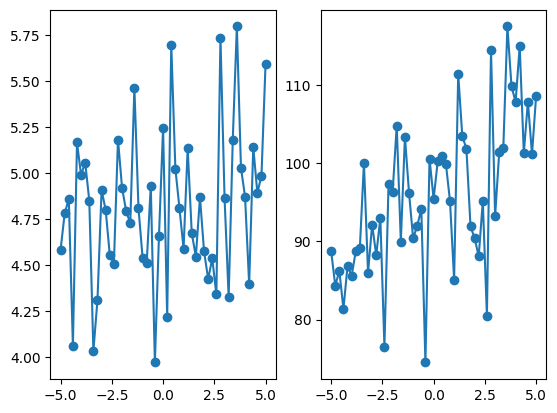

In [ ]:
mags = np.array(mags)
angs = np.array(angs)

angle_offsets = np.linspace(-5,5,51)
angle_offsets = np.delete(angle_offsets,misses)

plt.subplot(1,2,1)
plt.plot(angle_offsets,mags,'-o')
plt.subplot(1,2,2)
plt.plot(angle_offsets,angs,'-o')

Slope of Orientation Response: 2.0259171765911157
Offset of Orientation Response: 95.80971711441103


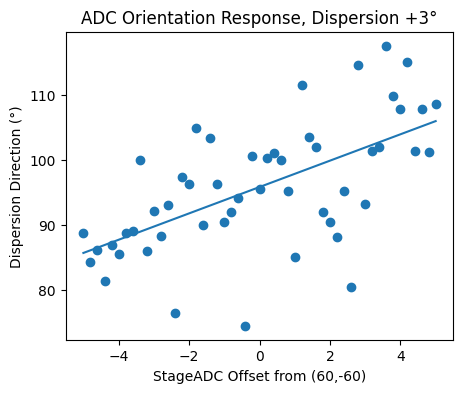

In [ ]:
#now fit the orientation response

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)

m1 , b1 = np.polyfit(angle_offsets,angs,deg=1)
plt.scatter(angle_offsets,angs)
linepoints = b1 + m1 * angle_offsets
plt.plot(angle_offsets, linepoints)
print(f'Slope of Orientation Response: {m1}')
print(f'Offset of Orientation Response: {b1}')


plt.title('ADC Orientation Response, Dispersion +3°')
plt.xlabel('StageADC Offset from (60,-60)')
plt.ylabel('Dispersion Direction (°)')
plt.show()

In [ ]:
#same thing but with less of a dispersion offset
cube2 = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/corotation_calibs/corotation_2offset.fits')
for img in cube2: #the dark subtraction isn't working so i had to median subtract the image... should I do this onsky?
       img -= np.median(img)

slope: 0.54
corresponding angle: 0.49 (rad) or 28.16°
least-squares solution: (-0.11773399969964878,2.8599862940872023)
Estimated dispersion direction 92.3573031437941°
Estimated dispersion magnitude 2.862408583178147


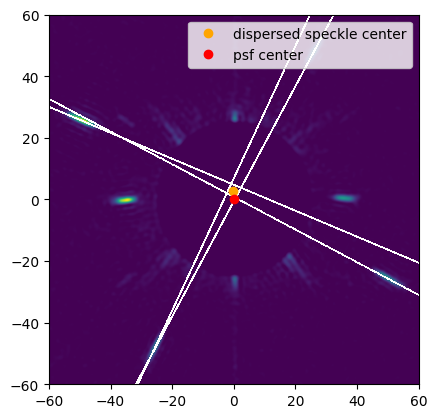

In [ ]:
h = ADC.filter_image(ADC.crop_image(cube2[0],mask_diam=50,extent=500))
q,r = ADC.slice_speckle_angle(h,0,print_updates=True,positions=True)
r = est_mag_dir(h,plotted=True,printed=True)

In [ ]:
mags =[]
angs = []
misses = []

for i,img in enumerate(cube2):
    img = ADC.filter_image(ADC.crop_image(img,extent=510))
    try:
        mag,ang = est_mag_dir(img,plotted=False)
        mags.append(mag)
        angs.append(ang)
    except: 
        misses.append(i)
        pass

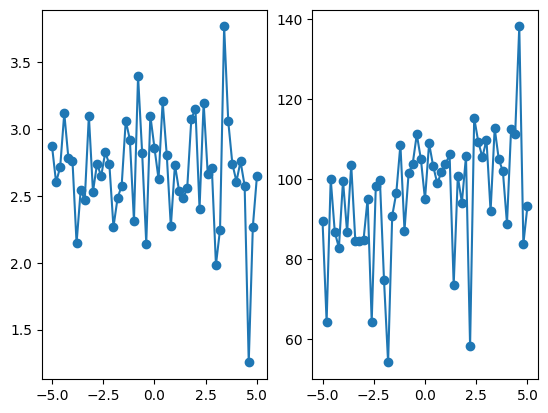

In [ ]:
mags = np.array(mags)
angs = np.array(angs)

angle_offsets = np.linspace(-5,5,51)
angle_offsets = np.delete(angle_offsets,misses)

plt.subplot(1,2,1)
plt.plot(angle_offsets,mags,'-o')
plt.subplot(1,2,2)
plt.plot(angle_offsets,angs,'-o')

Slope of Orientation Response: 2.163043045776423
Offset of Orientation Response: 95.89472766803439


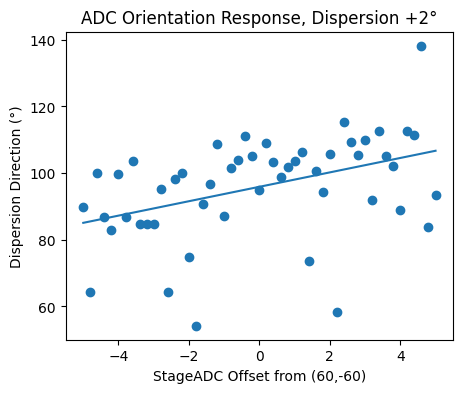

In [ ]:
#now fit the orientation response
plt.figure(figsize=(11,4))
plt.subplot(1,2,1)

m1 , b1 = np.polyfit(angle_offsets,angs,deg=1)
plt.scatter(angle_offsets,angs)
linepoints = b1 + m1 * angle_offsets
plt.plot(angle_offsets, linepoints)
print(f'Slope of Orientation Response: {m1}')
print(f'Offset of Orientation Response: {b1}')

plt.title('ADC Orientation Response, Dispersion +2°')
plt.xlabel('StageADC Offset from (60,-60)')
plt.ylabel('Dispersion Direction (°)')
plt.show()